In [3]:

import pandas as pd

# Load cleaned datasets from the parent folder
eda_transactions = pd.read_csv(
    "../Clean Data/finlora_transactions_clean.csv",
    parse_dates=["timestamp", "account_created_date"]
)

eda_accounts = pd.read_csv(
    "../Clean Data/finlora_accounts_clean.csv",
    parse_dates=["account_created_date"]
)

print("Transactions:", eda_transactions.shape)
print("Accounts:", eda_accounts.shape)
print("Fraud cases:", eda_transactions["is_fraud"].sum())


Transactions: (126000, 29)
Accounts: (7200, 8)
Fraud cases: 3352


FINLORA — FRAUD CLASS DISTRIBUTION
---------------------------------------------
Legitimate transactions: 122648
Fraudulent transactions: 3352

CLASS PERCENTAGES
Legitimate: 97.34%
Fraudulent: 2.66%


C:\Users\osato\AppData\Local\Temp\ipykernel_21256\3595966250.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Legitimate", "Fraud"])


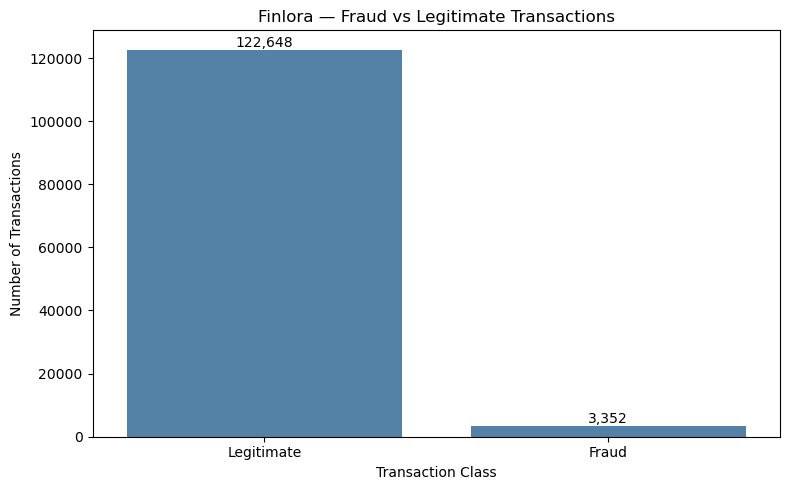

In [4]:

# STEP 3.2: Fraud class distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate class counts
fraud_counts = (
    eda_transactions["is_fraud"]
    .value_counts()
    .sort_index()
)

fraud_percentages = (
    eda_transactions["is_fraud"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("FINLORA — FRAUD CLASS DISTRIBUTION")
print("-" * 45)

print("Legitimate transactions:", fraud_counts[0])
print("Fraudulent transactions:", fraud_counts[1])

print("\nCLASS PERCENTAGES")
print(f"Legitimate: {fraud_percentages[0]:.2f}%")
print(f"Fraudulent: {fraud_percentages[1]:.2f}%")

# Create visualization
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=eda_transactions,
    x="is_fraud",
    order=[0, 1],
    color="steelblue"
)

ax.set_xticklabels(["Legitimate", "Fraud"])

plt.title("Finlora — Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:,.0f}",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


#### Findings — Fraud Class Distribution

The Finlora dataset contains 126,000 transactions, of which 122,648 (97.34%) are legitimate and 3,352 (2.66%) are fraudulent.

The bar chart reveals a substantial class imbalance.

**Business implications:**

- Fraud detection is a minority-class prediction problem.
- A model could achieve high accuracy while failing to identify fraudulent transactions.
- Precision and recall will be essential for evaluating fraud detection performance.
- Class weighting and stratified data splitting will be considered during modeling.

**Conclusion:** The dataset is highly imbalanced, and model evaluation must prioritize fraud detection effectiveness rather than overall accuracy alone.

FINLORA — TRANSACTION AMOUNT ANALYSIS
--------------------------------------------------

MEDIAN ABSOLUTE TRANSACTION AMOUNT BY CURRENCY


fraud_label,Fraud,Legitimate
currency,,
EUR,218.04,56.71
GBP,270.14,55.00
NGN,843766.00,108540.11
USD,245.00,65.45


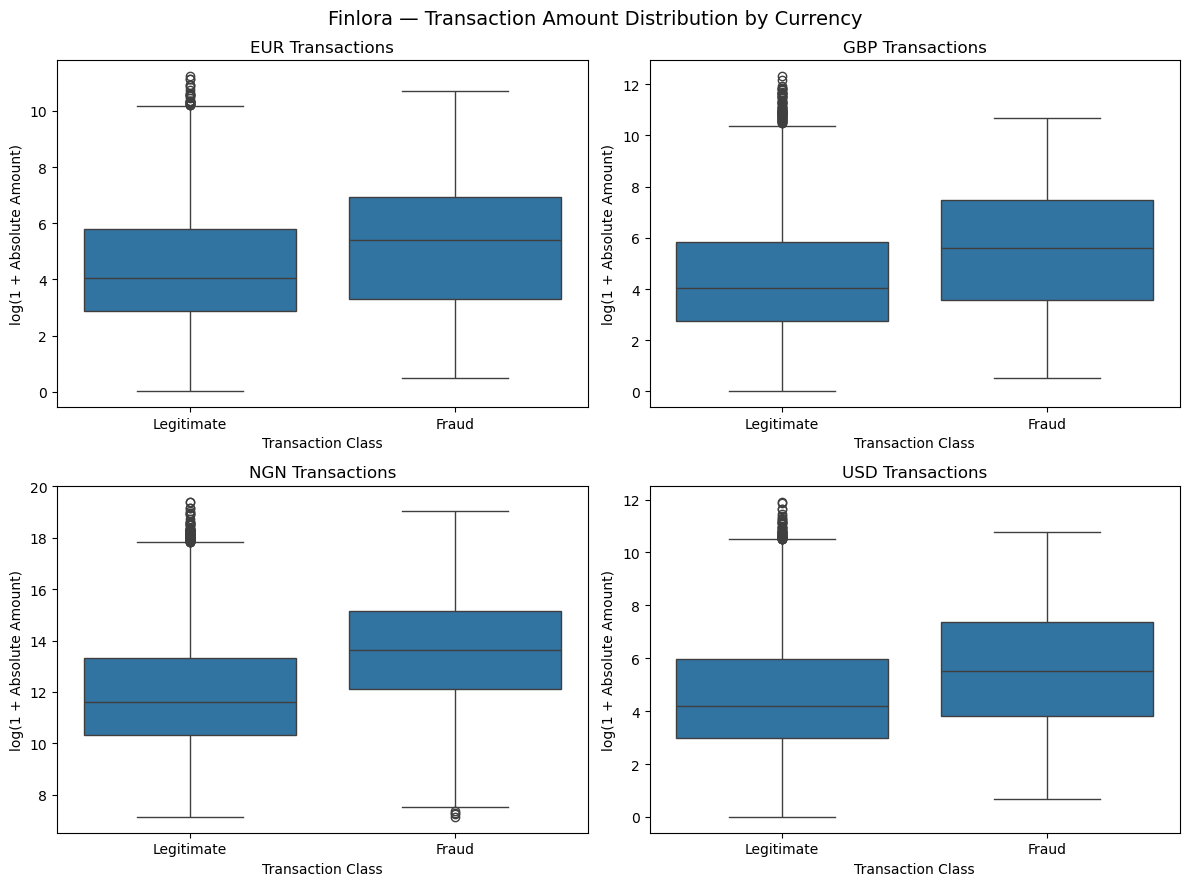

In [5]:

# STEP 3.3: Transaction amount analysis by currency

import numpy as np


# Temporary EDA dataset
amount_eda = eda_transactions[
    ["currency", "amount", "is_fraud"]
].copy()

# Absolute magnitude of transaction amounts
amount_eda["absolute_amount"] = amount_eda["amount"].abs()

# Log transformation for visualization
amount_eda["log_amount"] = np.log1p(
    amount_eda["absolute_amount"]
)

# Label fraud classes
amount_eda["fraud_label"] = amount_eda["is_fraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

print("FINLORA — TRANSACTION AMOUNT ANALYSIS")
print("-" * 50)

print("\nMEDIAN ABSOLUTE TRANSACTION AMOUNT BY CURRENCY")

median_amounts = amount_eda.groupby(
    ["currency", "fraud_label"]
)["absolute_amount"].median().unstack()

display(median_amounts.round(2))

# Visualize by currency
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, currency in zip(
    axes.flat,
    sorted(amount_eda["currency"].unique())
):
    subset = amount_eda[
        amount_eda["currency"] == currency
    ]

    sns.boxplot(
        data=subset,
        x="fraud_label",
        y="log_amount",
        order=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(f"{currency} Transactions")
    ax.set_xlabel("Transaction Class")
    ax.set_ylabel("log(1 + Absolute Amount)")

plt.suptitle(
    "Finlora — Transaction Amount Distribution by Currency",
    fontsize=14
)

plt.tight_layout()
plt.show()


##### Findings — Transaction Amount Analysis

Transaction amount distributions were compared between fraudulent and legitimate transactions across EUR, GBP, NGN, and USD.

**Key findings:**

- Fraudulent transactions generally have higher median absolute amounts across all four currencies.
- Transaction amounts exhibit substantial skewness and extreme values.
- Legitimate and fraudulent amount distributions overlap, indicating that transaction amount alone is insufficient to identify fraud.
- Differences in currency scales make currency-aware analysis and preprocessing necessary.

**Business implications:**

Unusually large transaction amounts may increase fraud risk, but the model should evaluate them alongside historical spending behavior, device information, transaction velocity, and other relevant features.

**Feature engineering considerations:**

- Retain the original transaction amount.
- Consider logarithmic transformations to reduce skewness.
- Account for currency differences during preprocessing.
- Preserve potentially informative transaction outliers.

**Conclusion:** Transaction amount is a potentially useful fraud predictor, particularly when interpreted relative to the customer's typical spending behavior.

FINLORA — SPENDING RATIO ANALYSIS
---------------------------------------------

MEDIAN SPENDING RATIO BY FRAUD CLASS


fraud_label
Fraud         6.04
Legitimate    0.95
Name: amount_to_avg_ratio, dtype: float64

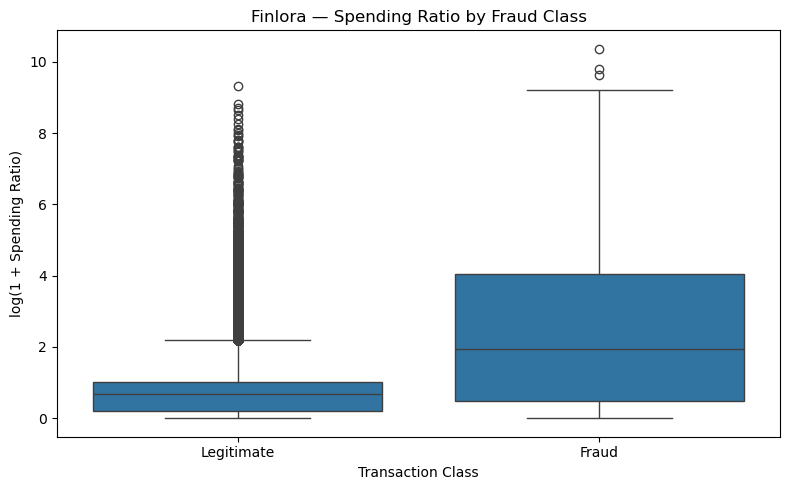


FRAUD RATE BY SPENDING RATIO RANGE


,transactions,fraud_cases,fraud_rate
ratio_range,,,
0–1,80707,1072,1.33
1–2,15777,255,1.62
2–5,14646,306,2.09
5–10,6524,172,2.64
10–50,6571,656,9.98
>50,1775,891,50.20


In [6]:

# STEP 3.4: Spending ratio analysis




ratio_eda = eda_transactions[
    ["amount_to_avg_ratio", "is_fraud"]
].copy()

ratio_eda["fraud_label"] = ratio_eda["is_fraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

# Log transformation for easier visualization
ratio_eda["log_ratio"] = np.log1p(
    ratio_eda["amount_to_avg_ratio"]
)

print("FINLORA — SPENDING RATIO ANALYSIS")
print("-" * 45)

print("\nMEDIAN SPENDING RATIO BY FRAUD CLASS")

display(
    ratio_eda.groupby("fraud_label")[
        "amount_to_avg_ratio"
    ].median()
)

# Compare distributions
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=ratio_eda,
    x="fraud_label",
    y="log_ratio",
    order=["Legitimate", "Fraud"]
)

plt.title("Finlora — Spending Ratio by Fraud Class")
plt.xlabel("Transaction Class")
plt.ylabel("log(1 + Spending Ratio)")

plt.tight_layout()
plt.show()

# Fraud rates across spending ratio ranges
ratio_bins = [-0.01, 1, 2, 5, 10, 50, np.inf]
ratio_labels = [
    "0–1", "1–2", "2–5",
    "5–10", "10–50", ">50"
]

ratio_eda["ratio_range"] = pd.cut(
    ratio_eda["amount_to_avg_ratio"],
    bins=ratio_bins,
    labels=ratio_labels
)

ratio_summary = ratio_eda.groupby(
    "ratio_range", observed=True
).agg(
    transactions=("is_fraud", "count"),
    fraud_cases=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean")
)

ratio_summary["fraud_rate"] = (
    ratio_summary["fraud_rate"] * 100
).round(2)

print("\nFRAUD RATE BY SPENDING RATIO RANGE")
display(ratio_summary)


##### Findings — Spending Ratio Analysis

The boxplot compares the transaction-to-average spending ratio between legitimate and fraudulent transactions using a logarithmic transformation.

**Key findings:**

- Fraudulent transactions generally have higher spending ratios than legitimate transactions.
- The spending-ratio distribution is more dispersed among fraudulent transactions.
- Extreme ratios occur in both transaction classes.
- The distributions overlap, indicating that spending ratio alone is insufficient for reliable fraud detection.

**Business implications:**

Transactions substantially exceeding an account's typical spending behavior may indicate elevated fraud risk.

**Feature engineering decision:**

Retain `amount_to_avg_ratio` as a potential predictive feature and consider a logarithmic transformation to reduce skewness.

Before modeling, verify that the historical spending baseline is available at transaction time.

**Conclusion:** Relative spending behavior appears to be an important fraud risk indicator in the Finlora dataset.

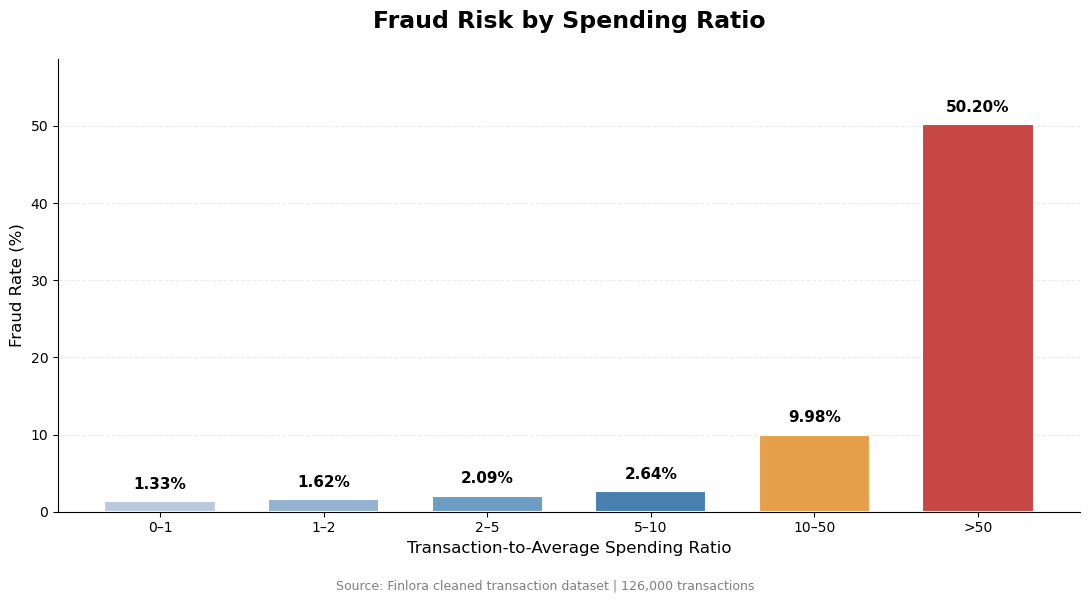

In [9]:

# STEP 3.4.1: Professional Spending Ratio vs Fraud Risk Chart

import pandas as pd
import matplotlib.pyplot as plt

# Define spending ratio ranges
ratio_bins = [-0.01, 1, 2, 5, 10, 50, float("inf")]
ratio_labels = ["0–1", "1–2", "2–5", "5–10", "10–50", ">50"]

# Create a temporary analysis dataset
ratio_chart = eda_transactions[
    ["amount_to_avg_ratio", "is_fraud"]
].copy()

ratio_chart["ratio_range"] = pd.cut(
    ratio_chart["amount_to_avg_ratio"],
    bins=ratio_bins,
    labels=ratio_labels,
    include_lowest=True
)

# Calculate fraud rate by spending ratio range
ratio_risk = (
    ratio_chart.groupby("ratio_range", observed=True)
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

ratio_risk["fraud_rate"] *= 100

# Color palette: highlight higher-risk ranges
colors = [
    "#B8CBDD",
    "#91B3D0",
    "#6E9DC3",
    "#477FB1",
    "#E6A04B",
    "#C74747"
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    ratio_risk["ratio_range"].astype(str),
    ratio_risk["fraud_rate"],
    color=colors,
    width=0.68,
    edgecolor="white",
    linewidth=1.5
)

# Percentage labels above bars
for bar, rate in zip(bars, ratio_risk["fraud_rate"]):
    ax.annotate(
        f"{rate:.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Professional styling
ax.set_title(
    "Fraud Risk by Spending Ratio",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel("Transaction-to-Average Spending Ratio", fontsize=12)
ax.set_ylabel("Fraud Rate (%)", fontsize=12)

ax.set_ylim(0, ratio_risk["fraud_rate"].max() * 1.17)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add source note
fig.text(
    0.5, 0.01,
    "Source: Finlora cleaned transaction dataset | 126,000 transactions",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


##### Business Insight — Spending Ratio and Fraud Risk

The visualization demonstrates a strong positive association between the transaction-to-average spending ratio and observed fraud rates.

Fraud rates increase gradually across lower spending-ratio ranges, followed by a substantial rise at ratios above 10.

Transactions with spending ratios greater than 50 exhibit the highest fraud rate at 50.20%, compared with 1.33% for transactions with ratios between 0 and 1.

**Business implication:** Spending ratios could help Finlora prioritize transactions for fraud investigation, particularly when a transaction substantially exceeds an account's historical spending behavior.

**Modeling consideration:** Retain `amount_to_avg_ratio` as a candidate predictive feature, subject to verification that its underlying historical data is available at prediction time.

**Conclusion:** Spending ratio is a promising indicator for fraud risk scoring and should be evaluated alongside other behavioral and transactional features.

 FRAUD ANALYSIS BY CHANNEL


,channel,transactions,fraud_cases,fraud_rate
0,API/Integration,13083,477,3.65
5,Web Dashboard,31330,926,2.96
3,Mobile App,41615,1045,2.51
1,Card Not Present,17422,408,2.34
2,Card Present,15080,338,2.24
4,USSD,7470,158,2.12


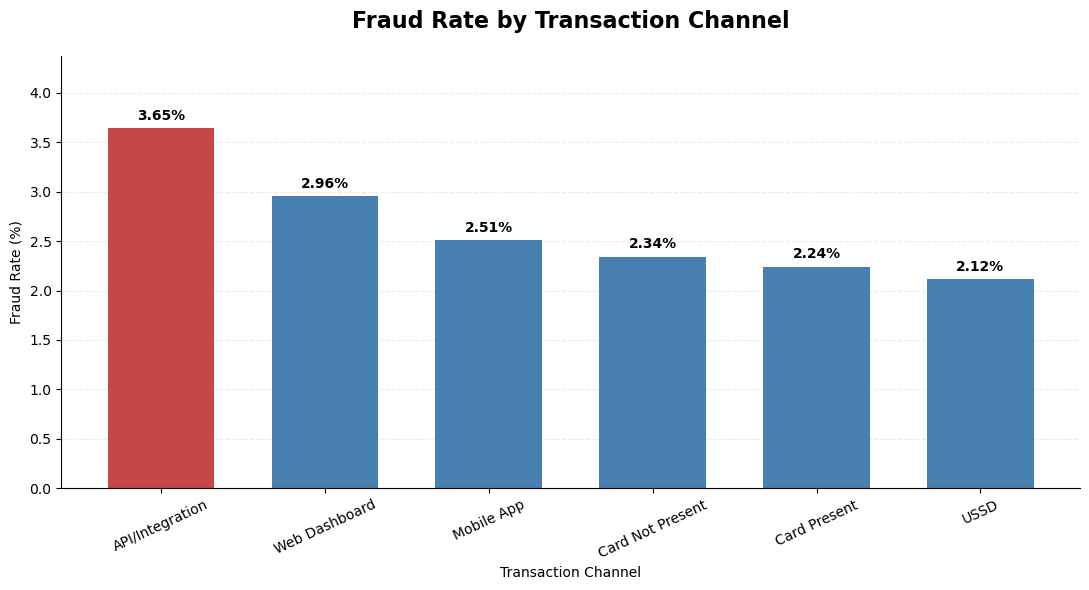

In [11]:

# STEP 3.5: Fraud rate by transaction channel



channel_summary = (
    eda_transactions.groupby("channel")
    .agg(
        transactions=("transaction_id", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

channel_summary["fraud_rate"] *= 100

channel_summary = channel_summary.sort_values(
    "fraud_rate", ascending=False
)

print(" FRAUD ANALYSIS BY CHANNEL")
display(channel_summary.round(2))

# Highlight channel with highest fraud rate
colors = [
    "#C74747" if i == 0 else "#477FB1"
    for i in range(len(channel_summary))
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    channel_summary["channel"],
    channel_summary["fraud_rate"],
    color=colors,
    width=0.65
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Fraud Rate by Transaction Channel",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Transaction Channel")
ax.set_ylabel("Fraud Rate (%)")
ax.tick_params(axis="x", rotation=25)

ax.set_ylim(0, channel_summary["fraud_rate"].max() * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


#### Findings — Fraud Analysis by Transaction Channel

Fraud rates vary across Finlora's six transaction channels.

**Key findings:**

- API/Integration has the highest fraud rate at 3.65%.
- Web Dashboard has the second-highest fraud rate at 2.96%.
- Mobile App records the largest number of fraud cases (1,045), reflecting its high transaction volume.
- USSD has the lowest observed fraud rate at 2.12%.

**Business implications:**

Fraud monitoring should consider both fraud rates and transaction volumes. Channels with higher fraud rates may warrant closer attention, while high-volume channels may generate larger absolute numbers of fraud cases.


**Conclusion:** Transaction channel is a potentially useful fraud risk indicator, although its predictive value must be validated alongside other features.

FRAUD BY DEVICE NOVELTY
---------------------------------------------


,device_category,transactions,fraud_cases,fraud_rate
0,Known Device,107771,2781,2.58
1,New Device,3895,228,5.85
2,Unknown Device,14334,343,2.39


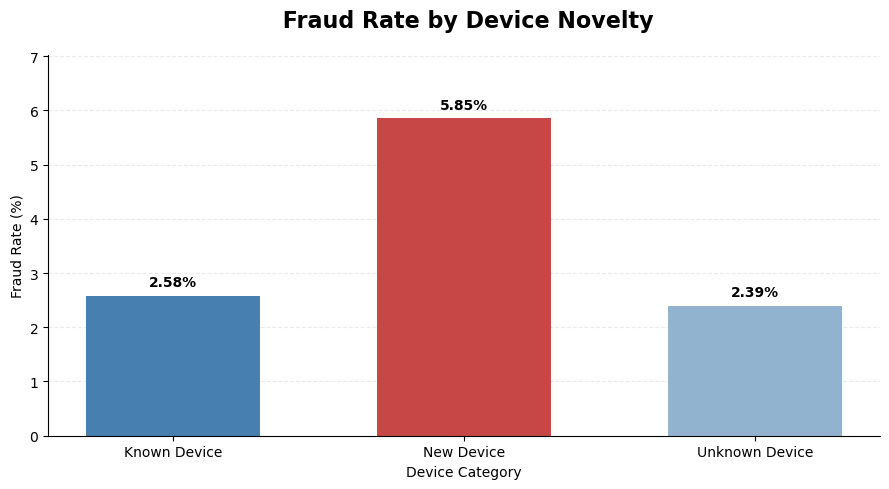

In [13]:

# STEP 3.6: Fraud analysis by device novelty


device_eda = eda_transactions[
    ["is_new_device", "is_fraud"]
].copy()

# Preserve unknown device status as a distinct category
device_eda["device_category"] = np.select(
    [
        device_eda["is_new_device"].eq(0),
        device_eda["is_new_device"].eq(1)
    ],
    [
        "Known Device",
        "New Device"
    ],
    default="Unknown Device"
)

device_summary = (
    device_eda.groupby("device_category")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reindex([
        "Known Device",
        "New Device",
        "Unknown Device"
    ])
    .reset_index()
)

device_summary["fraud_rate"] *= 100

print("FRAUD BY DEVICE NOVELTY")
print("-" * 45)

display(device_summary.round(2))

# Create professional bar chart
colors = ["#477FB1", "#C74747", "#91B3D0"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    device_summary["device_category"],
    device_summary["fraud_rate"],
    color=colors,
    width=0.6
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    " Fraud Rate by Device Novelty",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Device Category")
ax.set_ylabel("Fraud Rate (%)")
ax.set_ylim(0, device_summary["fraud_rate"].max() * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Device Novelty

The analysis compared fraud rates across known, new, and unknown devices.

**Key findings:**

- New devices have the highest observed fraud rate at 5.85%.
- Known devices have a fraud rate of 2.58%.
- Unknown devices have a fraud rate of 2.39%.
- The fraud rate for new devices is approximately 2.3 times the rate for known devices.
- Known-device transactions account for the largest number of fraud cases because of their higher transaction volume.

**Business implications:**

Transactions initiated from new devices may warrant additional fraud risk assessment. However, fraud occurs across all device categories, so device novelty should not be used as a standalone fraud rule.

**Conclusion:** Device novelty is associated with elevated fraud risk and may contribute useful information to Finlora's fraud scoring model.

 FRAUD BY TRANSACTION VELOCITY
--------------------------------------------------


,velocity_group,transactions,fraud_cases,fraud_rate
0,0 previous,124614,2071,1.66
1,1 previous,1333,1234,92.57
2,2+ previous,53,47,88.68


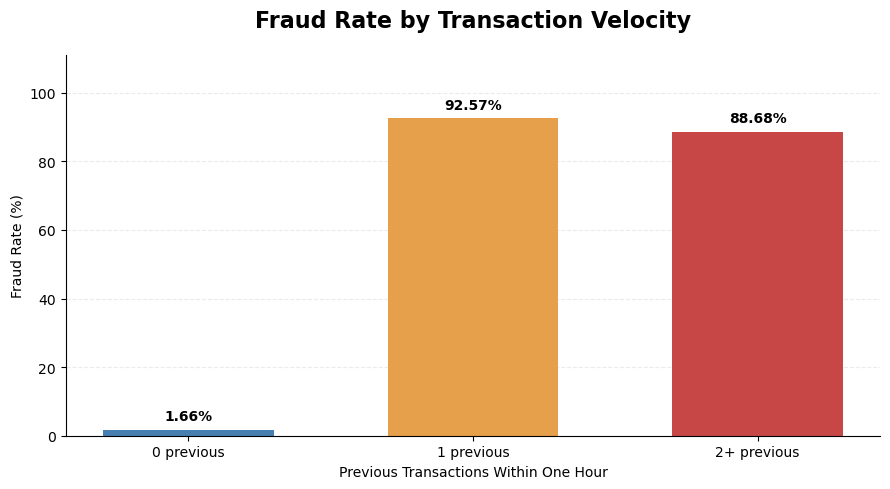

In [14]:

# STEP 3.7: Fraud analysis by transaction velocity


# Create temporary EDA dataset
velocity_eda = eda_transactions[
    ["transaction_velocity_1h", "is_fraud"]
].copy()

# Group velocity values
velocity_eda["velocity_group"] = np.select(
    [
        velocity_eda["transaction_velocity_1h"] == 0,
        velocity_eda["transaction_velocity_1h"] == 1,
        velocity_eda["transaction_velocity_1h"] >= 2
    ],
    [
        "0 previous",
        "1 previous",
        "2+ previous"
    ],
    default="Unknown"
)

velocity_summary = (
    velocity_eda.groupby("velocity_group")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reindex(["0 previous", "1 previous", "2+ previous"])
    .reset_index()
)

velocity_summary["fraud_rate"] *= 100

print(" FRAUD BY TRANSACTION VELOCITY")
print("-" * 50)

display(velocity_summary.round(2))

# Visualize fraud rates
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    velocity_summary["velocity_group"],
    velocity_summary["fraud_rate"],
    color=["#477FB1", "#E6A04B", "#C74747"],
    width=0.6
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Fraud Rate by Transaction Velocity",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Previous Transactions Within One Hour")
ax.set_ylabel("Fraud Rate (%)")
ax.set_ylim(0, max(velocity_summary["fraud_rate"]) * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Transaction Velocity

Transaction velocity was analyzed by counting previous transactions from the same account within a one-hour window.

**Key findings:**

- Transactions with zero previous transactions have a fraud rate of 1.66%.
- Transactions with one previous transaction have a fraud rate of 92.57%.
- Transactions with two or more previous transactions have a fraud rate of 88.68%.
- Transactions with velocity greater than zero represent approximately 1.10% of all transactions but contain approximately 38.22% of recorded fraud cases.

**Business implications:**

Rapid transaction activity is strongly associated with fraud in the Finlora dataset. Transaction velocity could help identify accounts requiring immediate fraud review.


**Conclusion:** Transaction velocity exhibits an exceptionally strong relationship with recorded fraud labels and may be an important fraud risk indicator, subject to leakage validation.

In [15]:

# STEP 3.8: Investigate velocity, status and fraud


velocity_diagnostic = eda_transactions[
    ["transaction_velocity_1h", "status", "is_fraud"]
].copy()

velocity_diagnostic["velocity_group"] = np.select(
    [
        velocity_diagnostic["transaction_velocity_1h"] == 0,
        velocity_diagnostic["transaction_velocity_1h"] == 1,
        velocity_diagnostic["transaction_velocity_1h"] >= 2
    ],
    ["0 previous", "1 previous", "2+ previous"],
    default="Unknown"
)

print("TRANSACTION STATUS BY VELOCITY")
print("-" * 50)

display(
    pd.crosstab(
        velocity_diagnostic["velocity_group"],
        velocity_diagnostic["status"],
        margins=True
    )
)

print("\nFRAUD RATE BY VELOCITY AND STATUS")

velocity_status_summary = (
    velocity_diagnostic.groupby(
        ["velocity_group", "status"]
    )
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

velocity_status_summary["fraud_rate"] = (
    velocity_status_summary["fraud_rate"] * 100
).round(2)

display(velocity_status_summary)


TRANSACTION STATUS BY VELOCITY
--------------------------------------------------


status,Completed,Declined,Reversed,All
velocity_group,,,,
0 previous,115843,5584,3187,124614
1 previous,825,42,466,1333
2+ previous,35,3,15,53
All,116703,5629,3668,126000



FRAUD RATE BY VELOCITY AND STATUS


,velocity_group,status,transactions,fraud_cases,fraud_rate
0,0 previous,Completed,115843,1272,1.10
1,0 previous,Declined,5584,58,1.04
2,0 previous,Reversed,3187,741,23.25
3,1 previous,Completed,825,731,88.61
4,1 previous,Declined,42,38,90.48
5,1 previous,Reversed,466,465,99.79
6,2+ previous,Completed,35,29,82.86
7,2+ previous,Declined,3,3,100.00
8,2+ previous,Reversed,15,15,100.00


##### Findings — Transaction Velocity Leakage Investigation

The relationship between transaction velocity and fraud was examined separately across Completed, Declined, and Reversed transaction statuses.

**Key findings:**

- Completed transactions with zero previous transactions have a fraud rate of 1.10%.
- Completed transactions with one previous transaction have a fraud rate of 88.61%.
- Completed transactions with two or more previous transactions have a fraud rate of 82.86%.
- High fraud rates among transactions with positive velocity persist across transaction statuses.

**Interpretation:**

The strong velocity–fraud association is not explained solely by transaction status. However, the analysis does not prove that the velocity feature is free from leakage or dataset-generation artifacts.

**Conclusion:** Transaction velocity is a highly informative candidate feature, but its unusually strong relationship with fraud requires cautious validation.

FRAUD BY CROSS-BORDER STATUS
---------------------------------------------


,transaction_type,transactions,fraud_cases,fraud_rate
0,Domestic,123455,3265,2.64
1,Cross-Border,2545,87,3.42


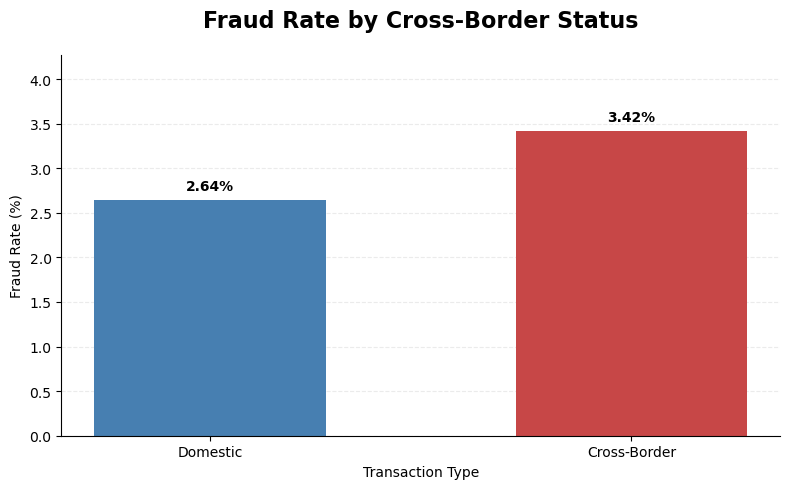

In [16]:

# STEP 3.9: Fraud analysis by cross-border status


cross_border_eda = eda_transactions[
    ["is_cross_border", "is_fraud"]
].copy()

cross_border_summary = (
    cross_border_eda.groupby("is_cross_border")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

cross_border_summary["fraud_rate"] *= 100

cross_border_summary["transaction_type"] = (
    cross_border_summary["is_cross_border"].map({
        0: "Domestic",
        1: "Cross-Border"
    })
)

print("FRAUD BY CROSS-BORDER STATUS")
print("-" * 45)

display(
    cross_border_summary[
        [
            "transaction_type",
            "transactions",
            "fraud_cases",
            "fraud_rate"
        ]
    ].round(2)
)

# Create bar chart
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    cross_border_summary["transaction_type"],
    cross_border_summary["fraud_rate"],
    color=["#477FB1", "#C74747"],
    width=0.55
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Fraud Rate by Cross-Border Status",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Transaction Type")
ax.set_ylabel("Fraud Rate (%)")

ax.set_ylim(
    0,
    cross_border_summary["fraud_rate"].max() * 1.25
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Cross-Border Status

The analysis compared fraudulent activity between domestic and cross-border transactions.

**Key findings:**

- Domestic transactions have a fraud rate of 2.64%.
- Cross-border transactions have a fraud rate of 3.42%.
- Cross-border transactions exhibit approximately 29% higher observed fraud prevalence than domestic transactions.
- Domestic transactions account for most fraud cases because they represent the majority of transaction volume.

**Business implications:**
Cross-border activity may indicate additional fraud exposure, but it should be evaluated alongside transaction amount, spending behavior, device novelty, and transaction velocity.

**Conclusion:** Cross-border status shows a modest positive association with recorded fraud and may provide supplementary information for fraud risk scoring.

FRAUD BY MERCHANT CATEGORY
--------------------------------------------------


,merchant_category,transactions,fraud_cases,fraud_rate
14,Wire Transfer,7639,579,7.58
8,Payroll Transfer,17117,957,5.59
1,Crypto Exchange,1692,88,5.20
12,Travel,7416,207,2.79
7,P2P Transfer,10715,272,2.54
6,Insurance,4528,106,2.34
2,Electronics,6173,128,2.07
3,Gambling/Gaming,951,17,1.79
13,Utilities,12444,221,1.78
5,Healthcare,4382,69,1.57


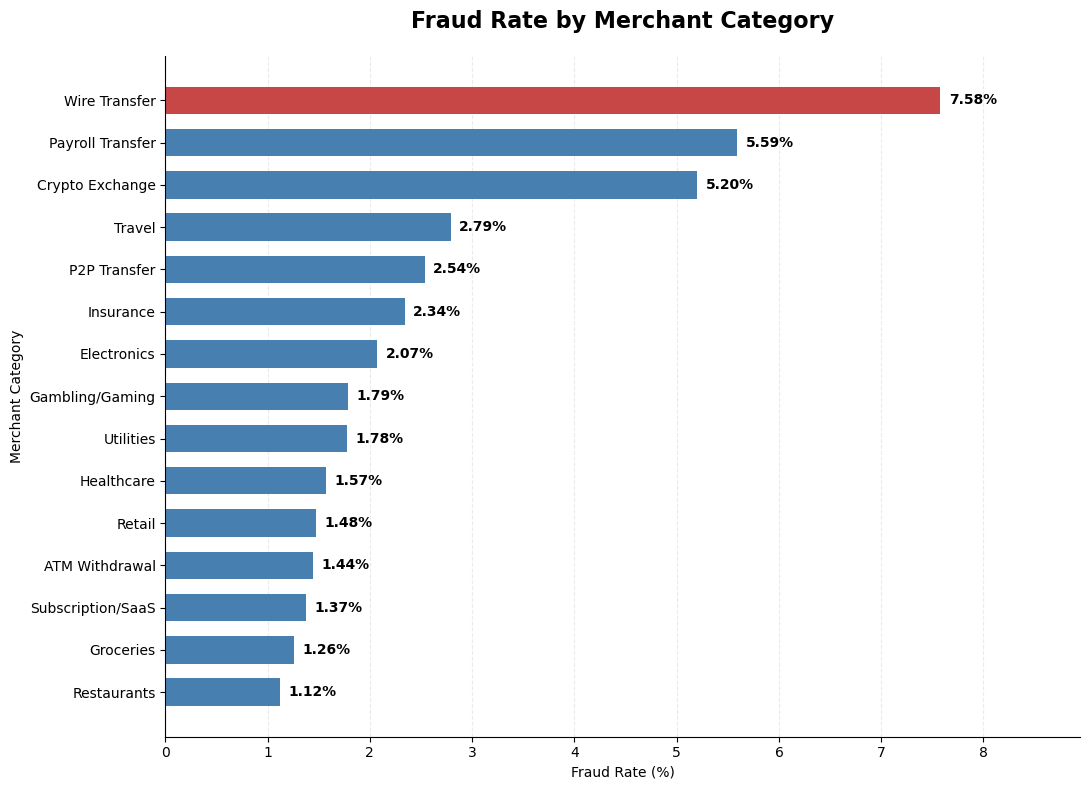

In [17]:

# STEP 3.10: Fraud analysis by merchant category


merchant_summary = (
    eda_transactions.groupby("merchant_category")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

merchant_summary["fraud_rate"] *= 100

merchant_summary = merchant_summary.sort_values(
    "fraud_rate", ascending=True
)

print("FRAUD BY MERCHANT CATEGORY")
print("-" * 50)

display(
    merchant_summary.sort_values(
        "fraud_rate", ascending=False
    ).round(2)
)

# Highlight the highest fraud-rate category
colors = [
    "#C74747" if rate == merchant_summary["fraud_rate"].max()
    else "#477FB1"
    for rate in merchant_summary["fraud_rate"]
]

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    merchant_summary["merchant_category"],
    merchant_summary["fraud_rate"],
    color=colors,
    height=0.65
)

# Display percentage labels
for bar in bars:
    ax.annotate(
        f"{bar.get_width():.2f}%",
        (
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Fraud Rate by Merchant Category",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Fraud Rate (%)")
ax.set_ylabel("Merchant Category")

ax.set_xlim(
    0,
    merchant_summary["fraud_rate"].max() * 1.18
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Merchant Category

Fraud prevalence was compared across 15 merchant categories in the Finlora transaction dataset.

**Key findings:**

- Wire Transfer has the highest observed fraud rate at 7.58%.
- Payroll Transfer has a fraud rate of 5.59% and the largest number of fraud cases (957).
- Crypto Exchange has a fraud rate of 5.20%.
- Restaurants, Groceries, and Subscription/SaaS have relatively low observed fraud rates of 1.12%, 1.26%, and 1.37%, respectively.

**Business implications:**
Transaction categories involving money movement, particularly wire and payroll transfers, warrant closer attention when prioritizing potential fraud investigations.

Both fraud prevalence and transaction volume should inform monitoring priorities.

**Conclusion:** Merchant category demonstrates meaningful variation in observed fraud prevalence and may contribute useful information to Finlora's fraud risk scoring model.

 FRAUD BY ACCOUNT TYPE


,account_type,transactions,fraud_cases,fraud_rate
0,Business,43888,1727,3.94
1,Individual,82112,1625,1.98



FRAUD BY KYC TIER


,kyc_tier,transactions,fraud_cases,fraud_rate
0,Tier1_Basic,22812,742,3.25
1,Tier2_Verified,64094,1750,2.73
2,Tier3_Enhanced,39094,860,2.20


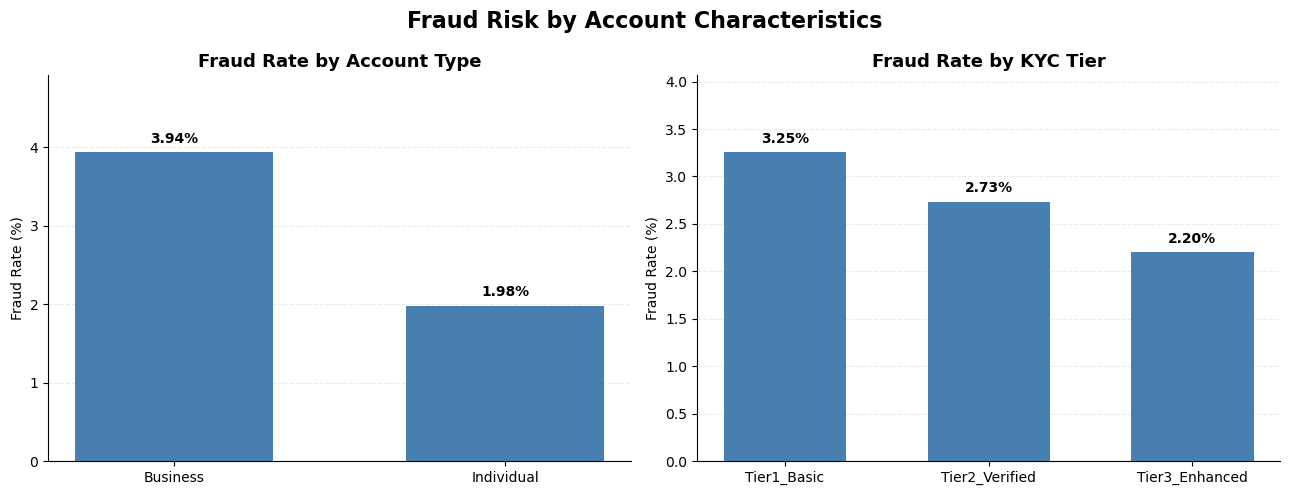

In [18]:

# STEP 3.11: Fraud analysis by account type and KYC tier


# Fraud summary by account type
account_type_summary = (
    eda_transactions.groupby("account_type")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

account_type_summary["fraud_rate"] *= 100

# Fraud summary by KYC tier
kyc_summary = (
    eda_transactions.groupby("kyc_tier")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

kyc_summary["fraud_rate"] *= 100

print(" FRAUD BY ACCOUNT TYPE")
display(account_type_summary.round(2))

print("\nFRAUD BY KYC TIER")
display(kyc_summary.round(2))

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, summary, category, title in [
    (
        axes[0],
        account_type_summary,
        "account_type",
        "Fraud Rate by Account Type"
    ),
    (
        axes[1],
        kyc_summary,
        "kyc_tier",
        "Fraud Rate by KYC Tier"
    )
]:
    bars = ax.bar(
        summary[category].astype(str),
        summary["fraud_rate"],
        color="#477FB1",
        width=0.6
    )

    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.2f}%",
            (bar.get_x() + bar.get_width() / 2,
             bar.get_height()),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontweight="bold"
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_ylabel("Fraud Rate (%)")
    ax.set_ylim(0, summary["fraud_rate"].max() * 1.25)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Fraud Risk by Account Characteristics",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Account Type and KYC Tier

The analysis examined fraud prevalence across Individual and Business accounts and the three KYC verification tiers.

**Account type findings:**

- Business accounts have a fraud rate of 3.94%.
- Individual accounts have a fraud rate of 1.98%.
- Business accounts exhibit approximately twice the observed fraud prevalence of Individual accounts.

**KYC tier findings:**

- Tier1_Basic: 3.25% fraud rate.
- Tier2_Verified: 2.73% fraud rate.
- Tier3_Enhanced: 2.20% fraud rate.
- Observed fraud prevalence decreases as KYC tier increases.

**Business implications:**

Account characteristics may help Finlora identify differences in customer transaction risk. Monitoring decisions should consider these attributes together with transaction behavior rather than relying on customer classifications alone.

**Conclusion:** Account type and KYC tier demonstrate associations with recorded fraud and may contribute useful information to the fraud risk scoring system.

 HOURLY FRAUD ANALYSIS
---------------------------------------------


,hour_of_day,transactions,fraud_cases,fraud_rate
0,0,1494,36,2.41
1,1,922,26,2.82
2,2,604,11,1.82
3,3,643,14,2.18
4,4,992,32,3.23
5,5,1947,28,1.44
6,6,3812,83,2.18
7,7,6337,162,2.56
8,8,8217,212,2.58
9,9,7514,187,2.49


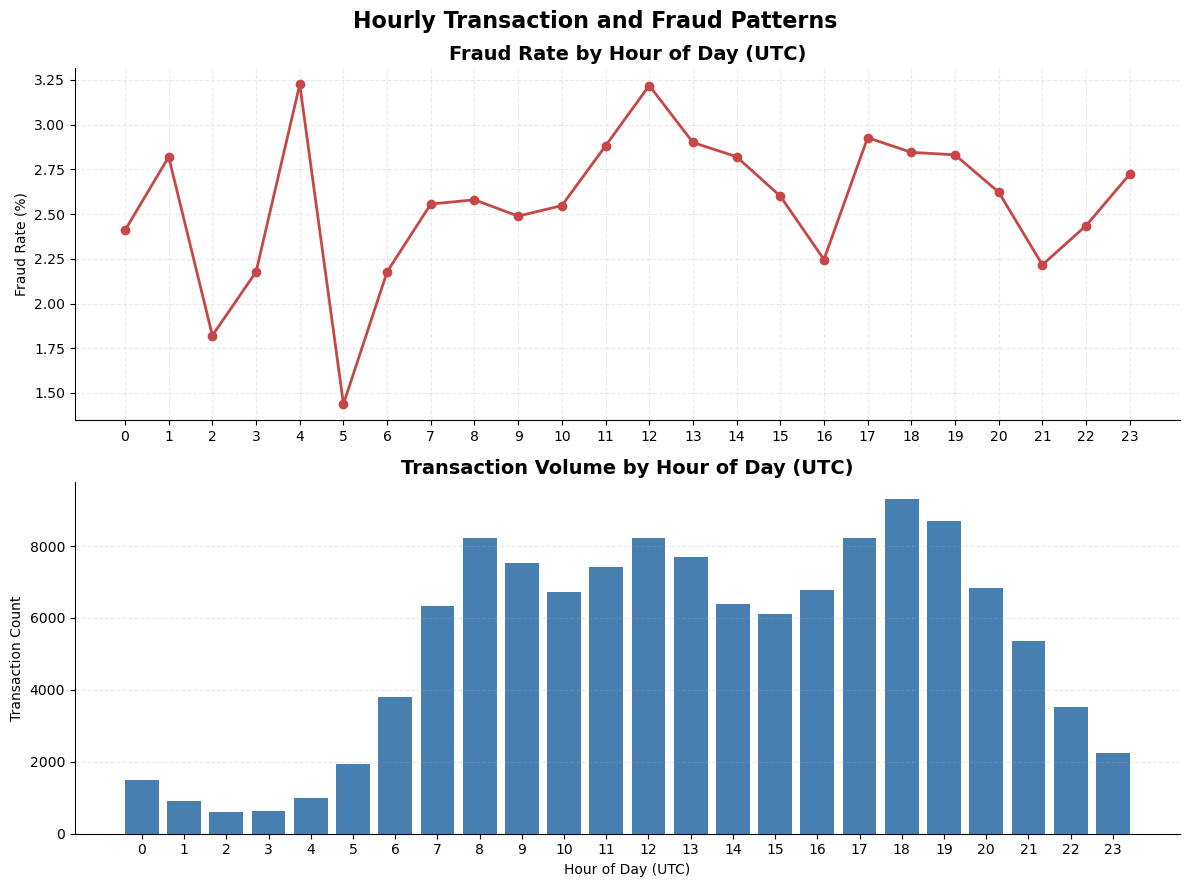

In [19]:

# STEP 3.12: Fraud analysis by hour of day


hourly_summary = (
    eda_transactions.groupby("hour_of_day")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
    .sort_values("hour_of_day")
)

hourly_summary["fraud_rate"] *= 100

print(" HOURLY FRAUD ANALYSIS")
print("-" * 45)

display(hourly_summary.round(2))

# Create two complementary visualizations
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Chart 1: Fraud rate by hour
axes[0].plot(
    hourly_summary["hour_of_day"],
    hourly_summary["fraud_rate"],
    marker="o",
    color="#C74747",
    linewidth=2
)

axes[0].set_title(
    "Fraud Rate by Hour of Day (UTC)",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Fraud Rate (%)")
axes[0].set_xticks(range(24))
axes[0].grid(alpha=0.25, linestyle="--")

# Chart 2: Transaction volume by hour
axes[1].bar(
    hourly_summary["hour_of_day"],
    hourly_summary["transactions"],
    color="#477FB1"
)

axes[1].set_title(
    "Transaction Volume by Hour of Day (UTC)",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Hour of Day (UTC)")
axes[1].set_ylabel("Transaction Count")
axes[1].set_xticks(range(24))
axes[1].grid(
    axis="y",
    alpha=0.25,
    linestyle="--"
)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Hourly Transaction and Fraud Patterns",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Hour of Day

The analysis examined hourly transaction volumes and fraud rates using UTC timestamps.

**Key findings:**

- Transaction volume peaks at 18:00 UTC, with 9,313 transactions.
- The highest observed fraud rate occurs at 04:00 UTC (3.23%), followed closely by 12:00 UTC (3.22%).
- The lowest observed fraud rate occurs at 05:00 UTC (1.44%).
- High transaction volume does not consistently correspond to higher fraud prevalence.
- Hourly fraud rates vary, but the differences are less pronounced than those observed for spending ratio and transaction velocity.

**Business implications:**

Transaction time may provide supplementary context for fraud monitoring. However, time of day alone is unlikely to be a reliable indicator of suspicious activity.

**Conclusion:** Hour of day may provide useful contextual information, but its predictive value must be established during model evaluation.

FRAUD BY DAY OF WEEK
---------------------------------------------


,day_of_week,transactions,fraud_cases,fraud_rate
0,Monday,17892,485,2.71
1,Tuesday,17925,500,2.79
2,Wednesday,17988,477,2.65
3,Thursday,17630,470,2.67
4,Friday,17934,475,2.65
5,Saturday,18229,481,2.64
6,Sunday,18402,464,2.52


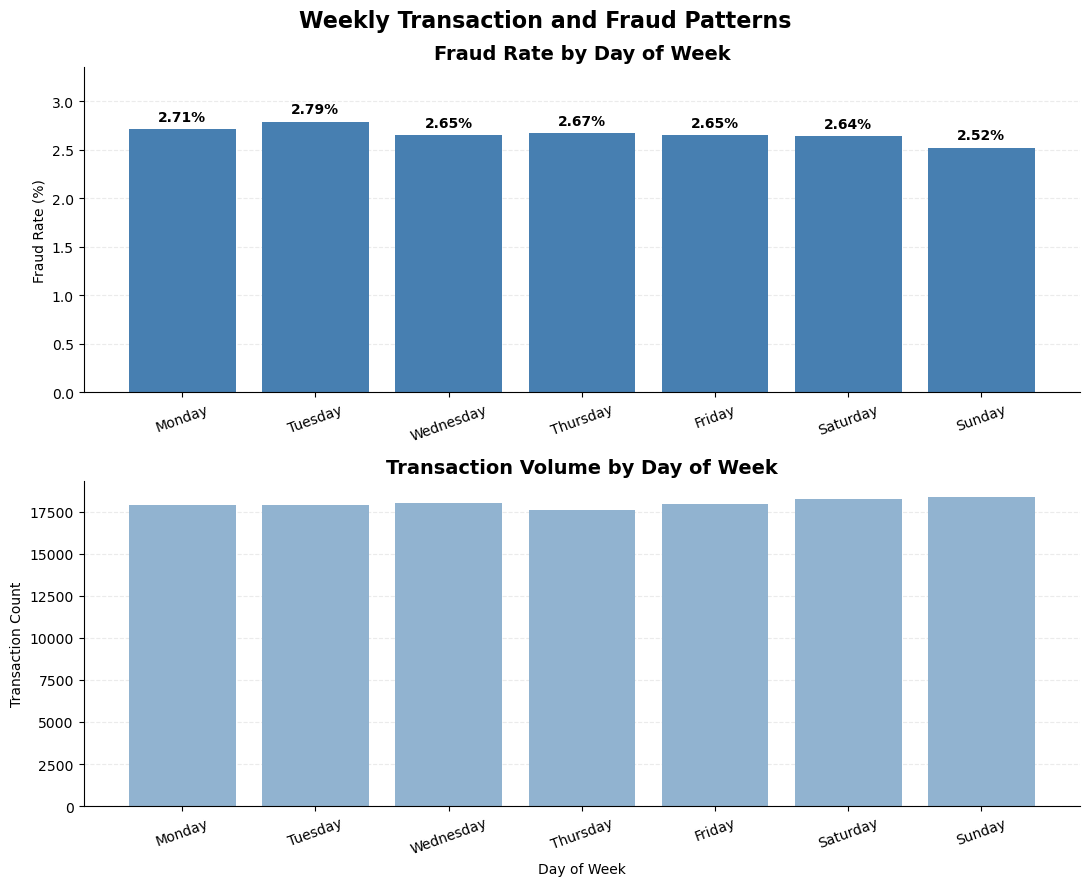

In [20]:

# STEP 3.13: Fraud analysis by day of week


day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_summary = (
    eda_transactions.groupby("day_of_week")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reindex(day_order)
    .reset_index()
)

day_summary["fraud_rate"] *= 100

print("FRAUD BY DAY OF WEEK")
print("-" * 45)

display(day_summary.round(2))

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

# Chart 1: Fraud rate
bars = axes[0].bar(
    day_summary["day_of_week"],
    day_summary["fraud_rate"],
    color="#477FB1"
)

for bar in bars:
    axes[0].annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2,
         bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

axes[0].set_title(
    "Fraud Rate by Day of Week",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Fraud Rate (%)")
axes[0].set_ylim(0, day_summary["fraud_rate"].max() * 1.2)

# Chart 2: Transaction volume
axes[1].bar(
    day_summary["day_of_week"],
    day_summary["transactions"],
    color="#91B3D0"
)

axes[1].set_title(
    "Transaction Volume by Day of Week",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Transaction Count")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Weekly Transaction and Fraud Patterns",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


##### Findings — Fraud Analysis by Day of Week

The analysis examined transaction volume and fraud prevalence across all seven days of the week.

**Key findings:**

- Tuesday has the highest observed fraud rate at 2.79%.
- Sunday has the lowest fraud rate at 2.52%.
- Sunday has the highest transaction volume, with 18,402 transactions.
- Transaction volumes are relatively consistent throughout the week.
- Fraud rates differ by only 0.27 percentage points between the highest-risk and lowest-risk days.

**Business implications:**

Fraud monitoring should operate consistently throughout the week rather than concentrating exclusively on specific days.

**Conclusion:** Day of week demonstrates only modest variation in observed fraud prevalence and is likely to provide supplementary rather than dominant predictive information.

 MONTHLY TRANSACTION AND FRAUD TRENDS
-------------------------------------------------------


,month,transactions,fraud_cases,fraud_rate
0,2025-02,5545,132,2.38
1,2025-03,6193,157,2.54
2,2025-04,5949,148,2.49
3,2025-05,6116,159,2.60
4,2025-06,5967,178,2.98
5,2025-07,6061,176,2.90
6,2025-08,6184,184,2.98
7,2025-09,5938,138,2.32
8,2025-10,6121,156,2.55
9,2025-11,10457,318,3.04



HIGHEST MONTHLY FRAUD RATE


,month,transactions,fraud_cases,fraud_rate
10,2025-12,14240,487,3.42
9,2025-11,10457,318,3.04
4,2025-06,5967,178,2.98


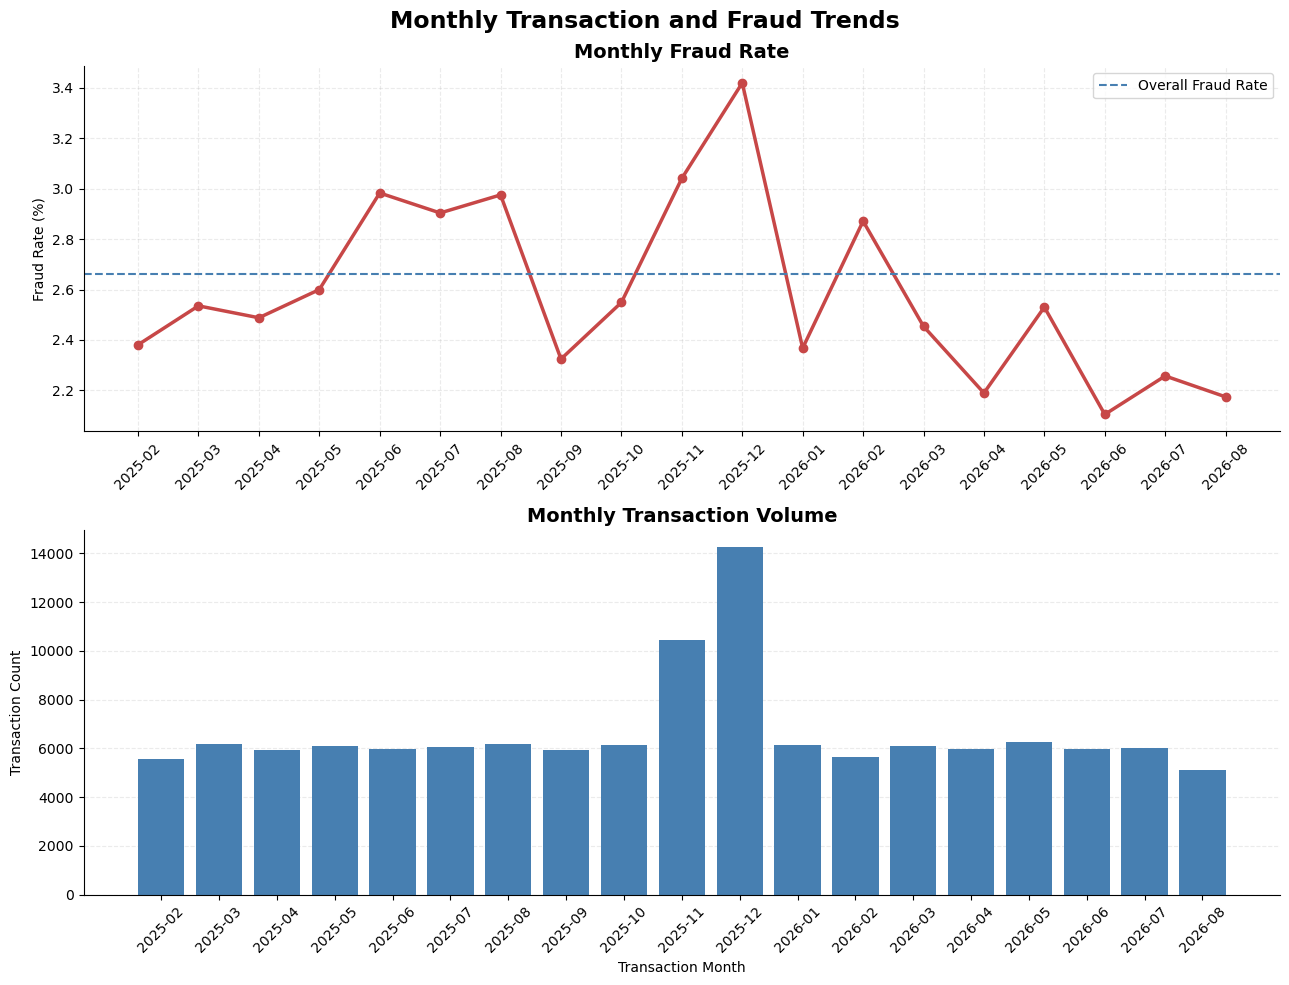

In [21]:

# STEP 3.15: Monthly Transaction and Fraud Trends


# Create a temporary dataset for monthly analysis
monthly_eda = eda_transactions[
    ["timestamp", "is_fraud"]
].copy()

# Ensure timestamps are datetime
monthly_eda["timestamp"] = pd.to_datetime(
    monthly_eda["timestamp"],
    utc=True
)

# Extract calendar month
monthly_eda["month"] = (
    monthly_eda["timestamp"]
    .dt.strftime("%Y-%m")
)

# Calculate monthly statistics
monthly_summary = (
    monthly_eda.groupby("month")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
    .sort_values("month")
)

monthly_summary["fraud_rate"] *= 100

print(" MONTHLY TRANSACTION AND FRAUD TRENDS")
print("-" * 55)

display(monthly_summary.round(2))

print("\nHIGHEST MONTHLY FRAUD RATE")

display(
    monthly_summary.nlargest(
        3, "fraud_rate"
    ).round(2)
)

# Create visualizations
fig, axes = plt.subplots(2, 1, figsize=(13, 10))

# Chart 1: Monthly fraud rate
axes[0].plot(
    monthly_summary["month"],
    monthly_summary["fraud_rate"],
    color="#C74747",
    marker="o",
    linewidth=2.5
)

axes[0].axhline(
    y=eda_transactions["is_fraud"].mean() * 100,
    color="#477FB1",
    linestyle="--",
    linewidth=1.5,
    label="Overall Fraud Rate"
)

axes[0].set_title(
    "Monthly Fraud Rate",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_ylabel("Fraud Rate (%)")
axes[0].legend()
axes[0].grid(alpha=0.25, linestyle="--")

# Chart 2: Monthly transaction volume
axes[1].bar(
    monthly_summary["month"],
    monthly_summary["transactions"],
    color="#477FB1"
)

axes[1].set_title(
    "Monthly Transaction Volume",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Transaction Month")
axes[1].set_ylabel("Transaction Count")
axes[1].grid(axis="y", alpha=0.25, linestyle="--")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.suptitle(
    "Monthly Transaction and Fraud Trends",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Findings — Monthly Transaction and Fraud Trends

The analysis examined monthly transaction volumes and fraud prevalence from February 2025 through August 2026.

**Key findings:**

- December 2025 recorded the highest fraud rate at 3.42% and the highest transaction volume of 14,240.
- November 2025 also exhibited elevated transaction volume and a fraud rate of 3.04%.
- Fraud rates fluctuate over time rather than following a consistent upward or downward trend.
- Most months have substantially lower transaction volumes than the November–December 2025 period.

**Business implications:**

Finlora should monitor monthly fraud rates and transaction activity to identify changes in risk exposure.

**Conclusion:** Fraud prevalence and transaction volumes exhibit temporal variation, supporting the need for ongoing model monitoring and time-aware evaluation.

FINLORA — BEHAVIORAL FEATURE INTERACTIONS
-------------------------------------------------------


,spending_group,device_group,transactions,fraud_cases,fraud_rate
1,High Ratio (>10),New Device,247,107,43.32
2,High Ratio (>10),Unknown Device,1045,190,18.18
0,High Ratio (>10),Known Device,7054,1250,17.72
4,Lower Ratio (≤10),New Device,3648,121,3.32
3,Lower Ratio (≤10),Known Device,100717,1531,1.52
5,Lower Ratio (≤10),Unknown Device,13289,153,1.15


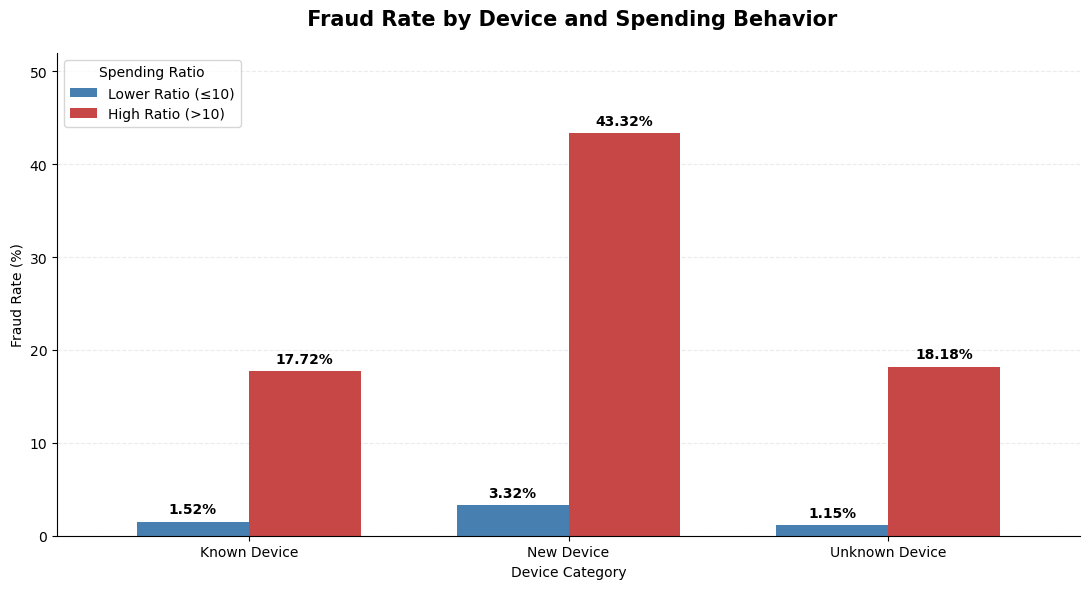

In [23]:


# STEP 3.16: Behavioral feature interaction analysis


interaction_eda = eda_transactions[
    ["amount_to_avg_ratio", "is_new_device", "is_fraud"]
].copy()

# Create spending-ratio groups
interaction_eda["spending_group"] = np.where(
    interaction_eda["amount_to_avg_ratio"] > 10,
    "High Ratio (>10)",
    "Lower Ratio (≤10)"
)

# Preserve all three device categories
interaction_eda["device_group"] = np.select(
    [
        interaction_eda["is_new_device"].eq(0),
        interaction_eda["is_new_device"].eq(1)
    ],
    [
        "Known Device",
        "New Device"
    ],
    default="Unknown Device"
)

# Summarize fraud by behavioral combinations
interaction_summary = (
    interaction_eda.groupby(
        ["spending_group", "device_group"]
    )
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

interaction_summary["fraud_rate"] *= 100

print("FINLORA — BEHAVIORAL FEATURE INTERACTIONS")
print("-" * 55)

display(
    interaction_summary.sort_values(
        "fraud_rate", ascending=False
    ).round(2)
)

# Prepare data for visualization
plot_data = interaction_summary.pivot(
    index="device_group",
    columns="spending_group",
    values="fraud_rate"
).reindex([
    "Known Device",
    "New Device",
    "Unknown Device"
])

plot_data = plot_data[
    ["Lower Ratio (≤10)", "High Ratio (>10)"]
]

# Create grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#477FB1", "#C74747"],
    width=0.7
)

for bar in ax.patches:
    height = bar.get_height()
    if np.isfinite(height):
        ax.annotate(
            f"{height:.2f}%",
            (
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

ax.set_title(
    " Fraud Rate by Device and Spending Behavior",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Device Category")
ax.set_ylabel("Fraud Rate (%)")
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Spending Ratio",
    loc="upper left"
)

ax.set_ylim(
    0,
    interaction_summary["fraud_rate"].max() * 1.2
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


##### Findings — Behavioral Feature Interaction Analysis

The analysis examined the combined relationship between device novelty, transaction-to-average spending ratio, and recorded fraud.

**Key findings:**

- New-device transactions with spending ratios above 10 have the highest fraud rate at 43.32% (107 fraud cases among 247 transactions).
- Known-device transactions with spending ratios above 10 have a fraud rate of 17.72%.
- Unknown-device transactions with spending ratios above 10 have a fraud rate of 18.18%.
- For new devices, fraud prevalence increases from 3.32% at ratios of 10 or below to 43.32% above 10.
- Higher spending ratios are associated with elevated fraud prevalence across all device categories.

**Business implications:**

Finlora may benefit from evaluating unusual spending behavior and device novelty together when prioritizing transactions for fraud investigation.


**Conclusion:** Combining device novelty and abnormal spending behavior identifies a transaction group with particularly high observed fraud prevalence, suggesting potentially useful interaction effects.

 ACCOUNT-LEVEL FRAUD CONCENTRATION
-------------------------------------------------------
Active accounts: 7144
Accounts with at least one fraud: 1762
Accounts without recorded fraud: 5382

TOTAL FRAUD CASES: 3352

FRAUD CONCENTRATION BY TOP ACCOUNTS
Top 1% of active accounts (72 accounts): 31.80% of fraud cases
Top 5% of active accounts (358 accounts): 52.86% of fraud cases
Top 10% of active accounts (715 accounts): 68.76% of fraud cases
Top 20% of active accounts (1429 accounts): 90.07% of fraud cases


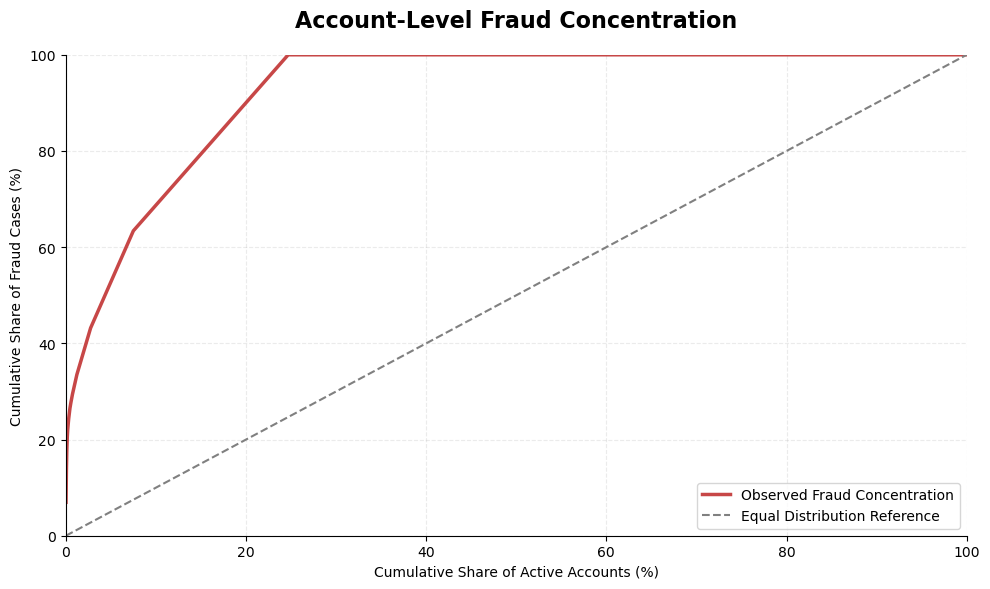


TOP 10 ACCOUNTS BY FRAUD COUNT


,account_id,transactions,fraud_cases,fraud_rate,cumulative_fraud_share,cumulative_account_share
0,FLR-ACC-101374,1497,233,15.56,6.95,0.01
1,FLR-ACC-100134,1064,100,9.40,9.93,0.03
2,FLR-ACC-101024,760,66,8.68,11.90,0.04
3,FLR-ACC-100827,751,62,8.26,13.75,0.06
4,FLR-ACC-105168,686,52,7.58,15.30,0.07
5,FLR-ACC-103606,599,40,6.68,16.50,0.08
6,FLR-ACC-102675,527,36,6.83,17.57,0.10
7,FLR-ACC-102017,433,31,7.16,18.50,0.11
8,FLR-ACC-102376,485,28,5.77,19.33,0.13
9,FLR-ACC-104094,449,21,4.68,19.96,0.14


In [24]:

# STEP 3.17: Account-Level Fraud Concentration

# Aggregate transactions and fraud cases by account
account_fraud = (
    eda_transactions.groupby("account_id")
    .agg(
        transactions=("is_fraud", "count"),
        fraud_cases=("is_fraud", "sum")
    )
    .reset_index()
)

account_fraud["fraud_rate"] = (
    account_fraud["fraud_cases"]
    / account_fraud["transactions"] * 100
)

# Sort by number of fraud cases
account_fraud = account_fraud.sort_values(
    "fraud_cases", ascending=False
).reset_index(drop=True)

total_accounts = len(account_fraud)
fraud_accounts = (account_fraud["fraud_cases"] > 0).sum()
total_fraud = account_fraud["fraud_cases"].sum()

print(" ACCOUNT-LEVEL FRAUD CONCENTRATION")
print("-" * 55)

print("Active accounts:", total_accounts)
print("Accounts with at least one fraud:", fraud_accounts)
print("Accounts without recorded fraud:",
      total_accounts - fraud_accounts)

print("\nTOTAL FRAUD CASES:", total_fraud)

# Share of fraud in top account groups
print("\nFRAUD CONCENTRATION BY TOP ACCOUNTS")

for percentage in [1, 5, 10, 20]:
    n_accounts = max(
        1, int(np.ceil(total_accounts * percentage / 100))
    )

    fraud_in_top = (
        account_fraud.head(n_accounts)["fraud_cases"].sum()
    )

    fraud_share = fraud_in_top / total_fraud * 100

    print(
        f"Top {percentage}% of active accounts "
        f"({n_accounts} accounts): {fraud_share:.2f}% "
        "of fraud cases"
    )

# Build cumulative concentration curve
account_fraud["cumulative_fraud_share"] = (
    account_fraud["fraud_cases"].cumsum()
    / total_fraud * 100
)

account_fraud["cumulative_account_share"] = (
    np.arange(1, total_accounts + 1)
    / total_accounts * 100
)

# Plot concentration curve
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    account_fraud["cumulative_account_share"],
    account_fraud["cumulative_fraud_share"],
    color="#C74747",
    linewidth=2.5,
    label="Observed Fraud Concentration"
)

ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Equal Distribution Reference"
)

ax.set_title(
    "Account-Level Fraud Concentration",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Cumulative Share of Active Accounts (%)")
ax.set_ylabel("Cumulative Share of Fraud Cases (%)")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(alpha=0.25, linestyle="--")
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print("\nTOP 10 ACCOUNTS BY FRAUD COUNT")
display(account_fraud.head(10).round(2))


#####   Findings — Account-Level Fraud Concentration

The analysis investigated how recorded fraudulent transactions are distributed across active Finlora accounts.

**Key findings:**

- 7,144 accounts have recorded transaction activity.
- 1,762 accounts have at least one recorded fraudulent transaction.
- 5,382 active accounts have no recorded fraud.
- The top 1% of active accounts account for 31.80% of all fraud cases.
- The top 5% account for 52.86%.
- The top 10% account for 68.76%.
- The top 20% account for 90.07%.

**Business implications:**

Recorded fraud is concentrated among a relatively small subset of accounts. Account-level investigation and monitoring may help Finlora identify repeated suspicious activity.
However, accounts with higher transaction volumes may naturally accumulate more fraud cases, so fraud counts should be considered alongside account activity.

**Conclusion:** Fraud is strongly concentrated across accounts, supporting the potential value of account-level monitoring and historical behavioral features in Finlora's fraud detection system.

#### 3.14 — Exploratory Data Analysis Summary

##### Dataset Overview

Finlora's cleaned dataset contains:

- **126,000 transactions**
- **7,200 accounts**
- **3,352 fraudulent transactions**
- **Overall fraud rate: 2.66%**

### Major Findings

| Feature | Main finding | Predictive consideration |
|---|---|---|
| Transaction amount | Fraudulent transactions generally involve larger amounts | Promising |
| Spending ratio | Fraud rate reaches 50.20% for ratios above 50 | Strong candidate |
| Transaction velocity | Transactions with positive velocity show fraud rates above 88% | Strong candidate; requires leakage validation |
| Device novelty | New-device fraud rate is 5.85% | Promising |
| Merchant category | Wire Transfer fraud rate is 7.58% | Promising |
| Transaction channel | API/Integration fraud rate is 3.65% | Promising |
| Account type | Business accounts show 3.94% fraud | Candidate |
| KYC tier | Fraud rates decrease from Tier1 to Tier3 | Candidate; evaluate fairness |
| Cross-border status | Cross-border fraud rate is 3.42% | Supplementary |
| Hour of day | Fraud rates vary modestly by hour | Supplementary |
| Day of week | Fraud rates range from 2.52% to 2.79% | Supplementary |

### Data Quality and Modeling Precautions

- The dataset is highly imbalanced, with only 2.66% fraudulent transactions.
- Extreme monetary values and spending ratios have been retained because they may contain important fraud signals.
- Missing device information has been preserved as a separate category.
- Transactions dated before their recorded account creation dates have been flagged.
- Final transaction status will be excluded from transaction-time model inputs because it may introduce target leakage.
- The existing account-age feature will be excluded from the initial model because of unresolved chronology inconsistencies.
- Transaction velocity and historical spending baselines require verification of their availability at scoring time.


##### Conclusion

Exploratory analysis identified meaningful associations between recorded fraud and several transaction characteristics, particularly spending ratio, transaction velocity, merchant category, and device novelty.

These findings provide a foundation for building explainable fraud classification models using Logistic Regression and Random Forest.

Predictive value and operational reliability must be confirmed through leakage-safe model validation.